# NeuroPath AI — Muscle Atrophy Predictor + PT Form Evaluator Training

These two features are trained together because they share the same IMU input (MPU6050)  
and a similar LSTM-based architecture.

---

## Part A: Muscle Atrophy Predictor
**Model:** Gradient Boosting Regressor  
**Logic:** Low spatial variance + steady resting HR over time → declining muscle engagement → atrophy risk  
**No external dataset needed** — uses sensor statistics + synthetic clinical data

## Part B: PT Form Evaluator  
**Model:** LSTM sequence classifier  
**Dataset:** Kaggle Physical Therapy IMU dataset (or synthetic exercise cycles)  
**Classes:** Correct Form vs 3 incorrect deviation types

### Folder layout
```
neuropath/
├── notebooks/
│   └── 04_atrophy_and_pt_form_train.ipynb   ← this file
├── models/
└── data/
    └── pt_exercise/                           ← optional: physical therapy CSVs here
        └── *.csv
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os, json, pickle
from scipy.fft import fft, fftfreq

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import classification_report, confusion_matrix

MODELS_DIR = '../models/'
PT_DIR     = '../data/pt_exercise/'
os.makedirs(MODELS_DIR, exist_ok=True)

print('Imports OK')
print(f'PT data directory exists: {os.path.exists(PT_DIR)}')

Imports OK
PT data directory exists: False


---
# PART A — Muscle Atrophy Predictor

In [2]:
# ── Synthetic clinical dataset ────────────────────────────────────────────────
# Based on: Suetta et al. 2004; Wall et al. 2013 (immobilisation muscle loss studies)
# Spatial variance → proxy for movement range and muscle activation

def generate_atrophy_dataset(n_samples: int = 2000, seed: int = 42) -> pd.DataFrame:
    rng = np.random.RandomState(seed)
    rows = []

    for _ in range(n_samples):
        immobilised_days  = rng.uniform(0, 30)          # 0–30 days
        spatial_variance  = rng.uniform(0.001, 2.0) * np.exp(-immobilised_days / 15)
        resting_hr        = rng.normal(72, 8)            # bpm
        hr_variability    = rng.uniform(5, 50) * np.exp(-immobilised_days / 20)
        age               = rng.randint(20, 80)
        activity_level    = np.clip(spatial_variance * 10, 0, 10)

        # Muscle mass loss %: clinical model
        # ~0.5% per day for first 2 weeks, ~0.3% per day thereafter
        # Amplified by age (sarcopenia), reduced by HR activity
        daily_loss = 0.5 if immobilised_days <= 14 else 0.3
        age_factor = 1.0 + (max(0, age - 40) * 0.01)  # +1% per year over 40
        activity_protection = np.clip(1.0 - activity_level * 0.05, 0.2, 1.0)
        atrophy_pct = (
            daily_loss * immobilised_days * age_factor * activity_protection
            + rng.normal(0, 0.5)  # biological noise
        )
        atrophy_pct = float(np.clip(atrophy_pct, 0, 25))  # 0–25% range

        rows.append({
            'spatial_variance'   : float(spatial_variance),
            'resting_hr'         : float(np.clip(resting_hr, 45, 110)),
            'hr_variability'     : float(hr_variability),
            'immobilised_days'   : float(immobilised_days),
            'age'                : float(age),
            'activity_level'     : float(activity_level),
            'atrophy_pct'        : atrophy_pct
        })

    return pd.DataFrame(rows)

atrophy_df = generate_atrophy_dataset()
print('Atrophy dataset:', atrophy_df.shape)
print(f'Atrophy % range: {atrophy_df["atrophy_pct"].min():.2f} – {atrophy_df["atrophy_pct"].max():.2f}')
atrophy_df.describe().round(3)

Atrophy dataset: (2000, 7)
Atrophy % range: 0.00 – 12.59


,spatial_variance,resting_hr,hr_variability,immobilised_days,age,activity_level,atrophy_pct
count,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000,2000.000
mean,0.441,71.951,14.207,14.875,50.148,4.084,4.874
std,0.384,8.276,9.403,8.646,17.479,3.080,2.714
min,0.000,45.000,1.156,0.004,20.000,0.004,0.000
25%,0.156,66.135,7.042,7.432,35.000,1.563,2.886
50%,0.326,71.922,11.964,14.917,51.000,3.264,4.928
75%,0.607,77.276,19.166,22.296,66.000,6.070,6.878
max,1.959,100.445,48.653,29.991,79.000,10.000,12.593


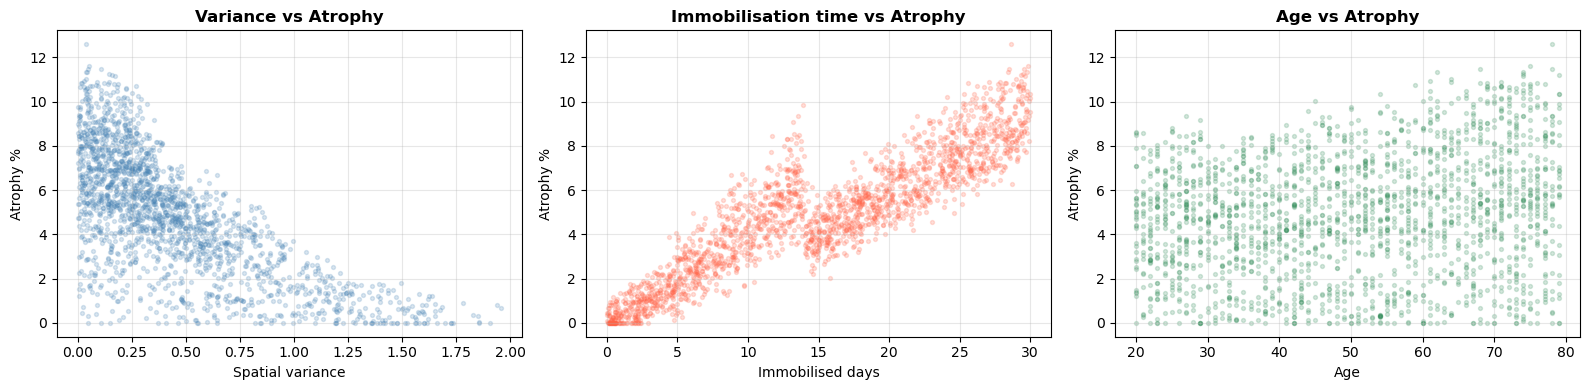

In [3]:
# Plot relationships
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].scatter(atrophy_df['spatial_variance'], atrophy_df['atrophy_pct'],
                alpha=0.2, s=8, c='steelblue')
axes[0].set_xlabel('Spatial variance'); axes[0].set_ylabel('Atrophy %')
axes[0].set_title('Variance vs Atrophy', fontweight='bold')

axes[1].scatter(atrophy_df['immobilised_days'], atrophy_df['atrophy_pct'],
                alpha=0.2, s=8, c='tomato')
axes[1].set_xlabel('Immobilised days'); axes[1].set_ylabel('Atrophy %')
axes[1].set_title('Immobilisation time vs Atrophy', fontweight='bold')

axes[2].scatter(atrophy_df['age'], atrophy_df['atrophy_pct'],
                alpha=0.2, s=8, c='seagreen')
axes[2].set_xlabel('Age'); axes[2].set_ylabel('Atrophy %')
axes[2].set_title('Age vs Atrophy', fontweight='bold')

for ax in axes: ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Gradient Boosting Regressor:
  MAE : 0.435%  (mean absolute error in atrophy percentage)
  R²  : 0.9617


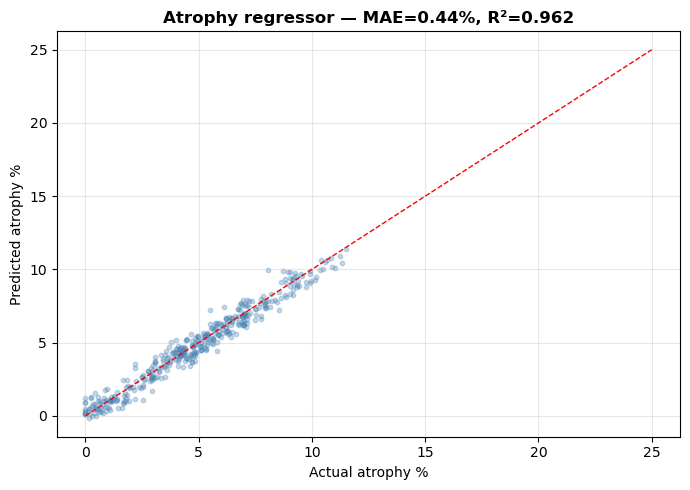


✅ Atrophy regressor saved.


In [4]:
feat_cols_atrophy = ['spatial_variance','resting_hr','hr_variability',
                     'immobilised_days','age','activity_level']

X_a = atrophy_df[feat_cols_atrophy].values
y_a = atrophy_df['atrophy_pct'].values

X_a_train, X_a_test, y_a_train, y_a_test = train_test_split(
    X_a, y_a, test_size=0.2, random_state=42
)

scaler_a = StandardScaler()
X_a_train_sc = scaler_a.fit_transform(X_a_train)
X_a_test_sc  = scaler_a.transform(X_a_test)

gbr = GradientBoostingRegressor(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    random_state=42
)
gbr.fit(X_a_train_sc, y_a_train)
y_a_pred = gbr.predict(X_a_test_sc)

mae = mean_absolute_error(y_a_test, y_a_pred)
r2  = r2_score(y_a_test, y_a_pred)
print(f'Gradient Boosting Regressor:')
print(f'  MAE : {mae:.3f}%  (mean absolute error in atrophy percentage)')
print(f'  R²  : {r2:.4f}')

# Prediction plot
plt.figure(figsize=(7, 5))
plt.scatter(y_a_test, y_a_pred, alpha=0.3, s=10, c='steelblue')
plt.plot([0, 25], [0, 25], 'r--', lw=1)
plt.xlabel('Actual atrophy %'); plt.ylabel('Predicted atrophy %')
plt.title(f'Atrophy regressor — MAE={mae:.2f}%, R²={r2:.3f}', fontweight='bold')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(MODELS_DIR + 'atrophy_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()

# Save
with open(MODELS_DIR + 'atrophy_regressor.pkl', 'wb') as f: pickle.dump(gbr, f)
with open(MODELS_DIR + 'atrophy_scaler.pkl', 'wb') as f: pickle.dump(scaler_a, f)

config_a = {
    'model_file'    : 'atrophy_regressor.pkl',
    'scaler_file'   : 'atrophy_scaler.pkl',
    'feature_names' : feat_cols_atrophy,
    'output'        : 'atrophy_percentage_0_to_25',
    'mae_test'      : round(float(mae), 3),
    'r2_test'       : round(float(r2), 4),
    'description'   : 'Gradient Boosting regressor for muscle atrophy prediction'
}
with open(MODELS_DIR + 'atrophy_model_config.json', 'w') as f: json.dump(config_a, f, indent=2)
print('\n✅ Atrophy regressor saved.')

---
# PART B — PT Form Evaluator (LSTM)

In [5]:
# ── Load real PT data or generate synthetic exercise cycles ──────────────────

PT_CLASSES = ['correct', 'overextension', 'insufficient_range', 'wrong_plane']
SEQ_LEN    = 100   # 2 seconds at 50 Hz
N_FEATURES = 6     # accel_x/y/z + gyro_x/y/z

def generate_synthetic_pt_dataset(n_per_class=500, seq_len=100, seed=42):
    """
    Synthesises exercise rep sequences for 4 form classes.
    Based on typical elbow flexion curl kinematics.
    """
    rng = np.random.RandomState(seed)
    X_list, y_list = [], []
    t = np.linspace(0, 2*np.pi, seq_len)

    patterns = {
        'correct':            {'amp': 1.0, 'freq': 1.0, 'noise': 0.1, 'asymm': 0.0},
        'overextension':      {'amp': 1.6, 'freq': 1.0, 'noise': 0.15,'asymm': 0.2},
        'insufficient_range': {'amp': 0.5, 'freq': 1.0, 'noise': 0.1, 'asymm': 0.0},
        'wrong_plane':        {'amp': 1.0, 'freq': 1.0, 'noise': 0.2, 'asymm': 0.5},
    }

    for class_idx, (cls, p) in enumerate(patterns.items()):
        for _ in range(n_per_class):
            individual_variation = rng.uniform(0.85, 1.15)
            base = p['amp'] * individual_variation * np.sin(p['freq'] * t)

            seq = np.column_stack([
                base + rng.normal(0, p['noise'], seq_len),          # accel_x
                0.3 * base + p['asymm'] * np.cos(t) + rng.normal(0, p['noise'], seq_len),  # accel_y
                0.1 * base + rng.normal(0, p['noise']*0.5, seq_len), # accel_z
                0.8 * np.cos(t) * p['amp'] + rng.normal(0, p['noise'], seq_len),  # gyro_x
                0.2 * np.sin(t) + p['asymm'] * base + rng.normal(0, p['noise'], seq_len),  # gyro_y
                0.1 * np.ones(seq_len) + rng.normal(0, p['noise']*0.3, seq_len),  # gyro_z
            ])
            X_list.append(seq)
            y_list.append(class_idx)

    return np.array(X_list), np.array(y_list)


# Try loading real data first
pt_csvs = []
if os.path.exists(PT_DIR):
    pt_csvs = [f for f in os.listdir(PT_DIR) if f.endswith('.csv')]

if pt_csvs:
    print(f'Found {len(pt_csvs)} PT CSV files — loading...')
    # Generic loader: assumes columns [accel_x,accel_y,accel_z,gyro_x,gyro_y,gyro_z,label]
    all_dfs = [pd.read_csv(os.path.join(PT_DIR, f)) for f in pt_csvs]
    pt_raw = pd.concat(all_dfs, ignore_index=True)
    print(f'Loaded: {pt_raw.shape}  Columns: {pt_raw.columns.tolist()}')
    # You may need to adapt this section based on actual column names
    # For now fall back to synthetic
    X_pt, y_pt = generate_synthetic_pt_dataset()
else:
    print('No PT CSV files found. Generating synthetic exercise dataset.')
    X_pt, y_pt = generate_synthetic_pt_dataset(n_per_class=600)

print(f'\nPT dataset: X={X_pt.shape}, y={y_pt.shape}')
print(f'Classes: {PT_CLASSES}')
for i, c in enumerate(PT_CLASSES):
    print(f'  {c}: {np.sum(y_pt == i)}')

No PT CSV files found. Generating synthetic exercise dataset.

PT dataset: X=(2400, 100, 6), y=(2400,)
Classes: ['correct', 'overextension', 'insufficient_range', 'wrong_plane']
  correct: 600
  overextension: 600
  insufficient_range: 600
  wrong_plane: 600


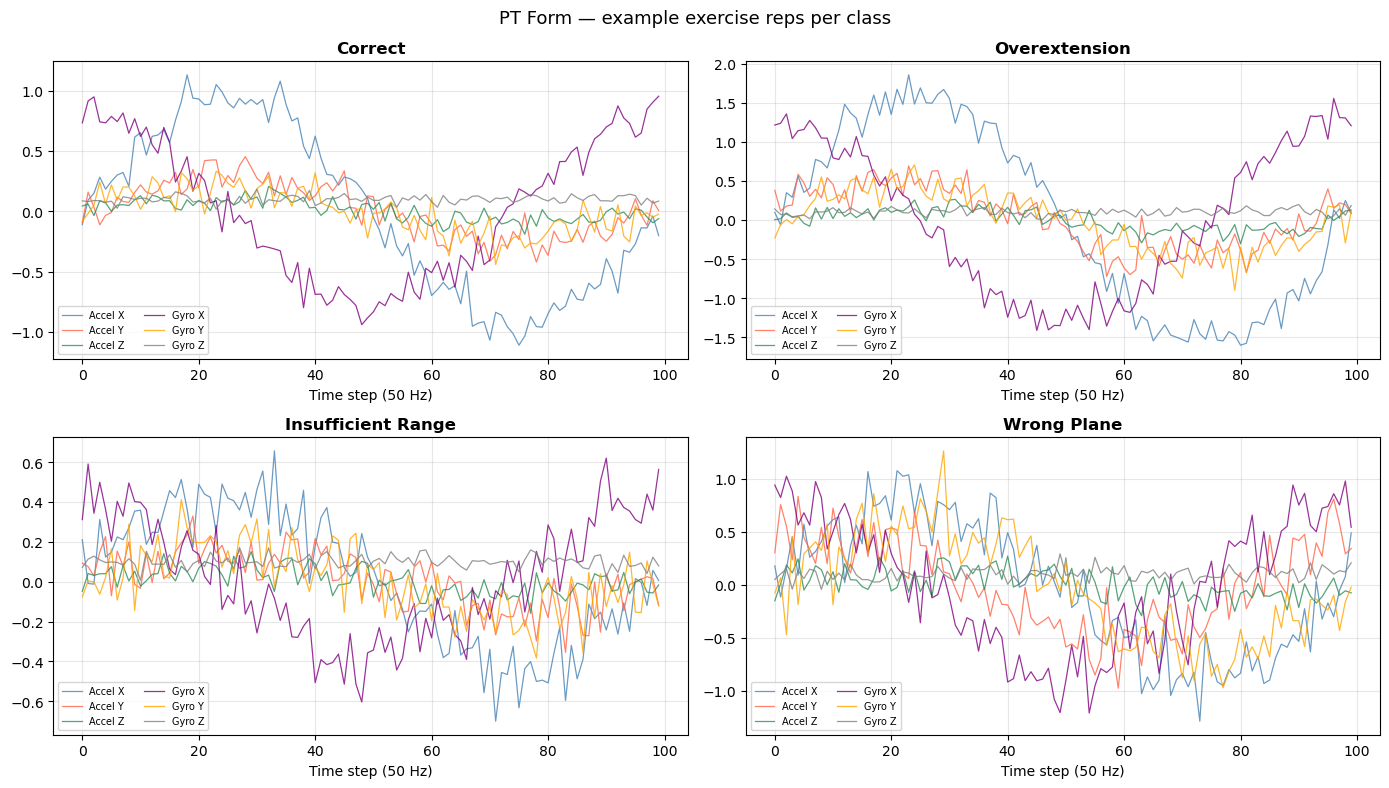

In [6]:
# Visualise one rep per class
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()
axis_names = ['Accel X','Accel Y','Accel Z','Gyro X','Gyro Y','Gyro Z']
colors_ax = ['steelblue','tomato','seagreen','purple','orange','gray']

for i, cls in enumerate(PT_CLASSES):
    idx = np.where(y_pt == i)[0][0]
    for j in range(N_FEATURES):
        axes[i].plot(X_pt[idx, :, j], label=axis_names[j],
                     color=colors_ax[j], linewidth=0.9, alpha=0.8)
    axes[i].set_title(f'{cls.replace("_"," ").title()}', fontweight='bold')
    axes[i].legend(fontsize=7, ncol=2)
    axes[i].set_xlabel('Time step (50 Hz)')
    axes[i].grid(alpha=0.3)

plt.suptitle('PT Form — example exercise reps per class', fontsize=13)
plt.tight_layout()
plt.show()

In [7]:
# ── Normalise + split ─────────────────────────────────────────────────────────
# Normalise each feature column across the dataset
X_flat = X_pt.reshape(-1, N_FEATURES)
scaler_pt = StandardScaler()
X_flat_sc = scaler_pt.fit_transform(X_flat)
X_pt_sc = X_flat_sc.reshape(X_pt.shape)

y_pt_cat = to_categorical(y_pt, num_classes=len(PT_CLASSES))

X_tr, X_te, y_tr, y_te = train_test_split(
    X_pt_sc, y_pt_cat, test_size=0.2, stratify=y_pt, random_state=42
)
print(f'Train: {X_tr.shape}  Test: {X_te.shape}')

# ── Build LSTM model ──────────────────────────────────────────────────────────
def build_pt_lstm(seq_len=100, n_features=6, n_classes=4):
    model = Sequential([
        Input(shape=(seq_len, n_features)),
        LSTM(64, return_sequences=True),
        Dropout(0.3),
        LSTM(32, return_sequences=False),
        Dropout(0.3),
        Dense(32, activation='relu'),
        Dense(n_classes, activation='softmax')
    ], name='pt_form_lstm')
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

lstm_model = build_pt_lstm(SEQ_LEN, N_FEATURES, len(PT_CLASSES))
lstm_model.summary()

Train: (1920, 100, 6)  Test: (480, 100, 6)


Model: "pt_form_lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 64)        │        18,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,780 (124.14 KB)

 Trainable params: 31,780 (124.14 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.4024 - loss: 1.2714

30/30 ━━━━━━━━━━━━━━━━━━━━ 7s 112ms/step - accuracy: 0.5427 - loss: 1.1001 - val_accuracy: 0.7500 - val_loss: 0.6452
Epoch 2/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.8123 - loss: 0.5029

30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.8932 - loss: 0.3503 - val_accuracy: 1.0000 - val_loss: 0.0663
Epoch 3/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 98ms/step - accuracy: 0.9797 - loss: 0.1150 - val_accuracy: 0.9396 - val_loss: 0.2059
Epoch 4/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.9917 - loss: 0.0474 - val_accuracy: 1.0000 - val_loss: 0.0097
Epoch 5/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 107ms/step - accuracy: 1.0000 - loss: 0.0139 - val_accuracy: 1.0000 - val_loss: 0.0045
Epoch 6/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 91ms/step - accuracy: 1.0000 - loss: 0.0082 - val_accuracy: 1.0000 - val_loss: 0.0026
Epoch 7/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 1.0000 - loss: 0.0057 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 8/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 102ms/step - accuracy: 1.0000 - loss: 0.0043 - val_accuracy: 1.0000 - val_loss: 0.0012
Epoch 9/40
30/30 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 1.0000 - loss: 0.0037 - val_accuracy: 1.0000 - val_loss:

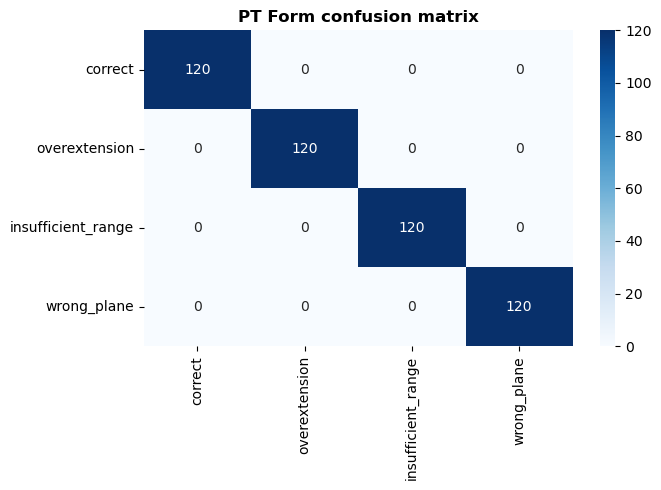

In [8]:
callbacks_pt = [
    EarlyStopping(monitor='val_accuracy', patience=8, restore_best_weights=True, mode='max'),
    ModelCheckpoint(MODELS_DIR + 'pt_form_best.h5', monitor='val_accuracy',
                    save_best_only=True, mode='max', verbose=0)
]

history_pt = lstm_model.fit(
    X_tr, y_tr,
    validation_data=(X_te, y_te),
    epochs=40,
    batch_size=64,
    callbacks=callbacks_pt,
    verbose=1
)

# Evaluation
y_te_labels = np.argmax(y_te, axis=1)
y_pr_labels = np.argmax(lstm_model.predict(X_te, verbose=0), axis=1)

print('\nPT Form LSTM:')
print(classification_report(y_te_labels, y_pr_labels, target_names=PT_CLASSES))

cm_pt = confusion_matrix(y_te_labels, y_pr_labels)
plt.figure(figsize=(7,5))
sns.heatmap(cm_pt, annot=True, fmt='d', cmap='Blues',
            xticklabels=PT_CLASSES, yticklabels=PT_CLASSES)
plt.title('PT Form confusion matrix', fontweight='bold')
plt.tight_layout()
plt.savefig(MODELS_DIR + 'pt_form_evaluation.png', dpi=120, bbox_inches='tight')
plt.show()

In [9]:
# Save
lstm_model.save(MODELS_DIR + 'pt_form_lstm.h5')
with open(MODELS_DIR + 'pt_form_scaler.pkl', 'wb') as f: pickle.dump(scaler_pt, f)

config_pt = {
    'model_file'    : 'pt_form_lstm.h5',
    'scaler_file'   : 'pt_form_scaler.pkl',
    'classes'       : PT_CLASSES,
    'n_classes'     : len(PT_CLASSES),
    'seq_len'       : SEQ_LEN,
    'n_features'    : N_FEATURES,
    'features'      : ['accel_x','accel_y','accel_z','gyro_x','gyro_y','gyro_z'],
    'sampling_hz'   : 50,
    'window_seconds': 2,
    'test_accuracy' : round(float(max(history_pt.history['val_accuracy'])), 4),
    'description'   : 'LSTM PT form classifier'
}
with open(MODELS_DIR + 'pt_form_model_config.json', 'w') as f: json.dump(config_pt, f, indent=2)

print('\n✅ All Part B files saved.')
print('\n── Summary of all models trained ──────────────────────────────')
for fname in sorted(os.listdir(MODELS_DIR)):
    size = os.path.getsize(os.path.join(MODELS_DIR, fname))
    print(f'  {fname:40s}  {size/1024:.1f} KB')


✅ All Part B files saved.

── Summary of all models trained ──────────────────────────────
  atrophy_evaluation.png                    50.9 KB
  atrophy_model_config.json                 0.4 KB
  atrophy_regressor.pkl                     1205.2 KB
  atrophy_scaler.pkl                        0.6 KB
  fall_best_checkpoint.h5                   12840.3 KB
  fall_detection_cnn.h5                     12840.3 KB
  fall_evaluation.png                       69.7 KB
  fall_model_config.json                    0.4 KB
  fall_training_curves.png                  75.9 KB
  pt_form_best.h5                           416.0 KB
  pt_form_evaluation.png                    35.1 KB
  pt_form_lstm.h5                           416.0 KB
  pt_form_model_config.json                 0.5 KB
  pt_form_scaler.pkl                        0.6 KB
  stress_classifier.pkl                     679.5 KB
  stress_evaluation.png                     30.8 KB
  stress_label_encoder.pkl                  0.3 KB
  stress_model_conf